# Solver interfaces

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/TuLLI-AI/symprog/blob/main/notebooks/solver_interfaces.ipynb)

A `Solver` builds formulas using a lower-level **solver interface** (or *mapper*), which wraps a particular library for representing and reasoning about Boolean formulas. All interfaces share the same methods:

- `Variables`, and the Boolean operators `And`, `Or`, `Not`, `Implies` and `Biconditional`, for building formulas;
- `SAT`, `Count` and `Models`, for satisfiability, model counting and model enumeration;
- `BuildFormula`, which (for diagram-based interfaces) also returns a [Graphviz](https://graphviz.org/) drawing.

| Interface | Library | Notes |
| --- | --- | --- |
| `sdd` (default) | [pysdd](https://github.com/ML-KULeuven/PySDD) | [Sentential Decision Diagrams](https://www.ijcai.org/Proceedings/11/Papers/143.pdf); the only interface with weighted inference |
| `bdd` | [dd](https://github.com/tulip-control/dd) | [Binary Decision Diagrams](https://apps.dtic.mil/sti/pdfs/ADA470446.pdf) |
| `z3` | [z3](https://github.com/Z3Prover/z3) | SAT/SMT solving ([De Moura and Bjørner 2008](https://link.springer.com/chapter/10.1007/978-3-540-78800-3_24)) |
| `sympy` | [sympy](https://docs.sympy.org/latest/modules/logic.html) | symbolic Boolean algebra |
| `pysat` | [PySAT](https://pysathq.github.io/) | access to many state-of-the-art SAT solvers |

## Setup

If `symprog` is not installed, the notebook uses the version in this repository.

In [1]:
# %pip install -q "symprog[notebooks]"

## use the installed symprog, or else the version in this repository
try:
    import symprog
except ImportError:
    import pathlib, sys
    repo = next((p for p in [pathlib.Path.cwd(), *pathlib.Path.cwd().parents] if (p / "symprog" / "__init__.py").exists()), None)
    if repo is None:
        raise ImportError("symprog is not installed: pip install symprog, or run this notebook from the symprog repository")
    sys.path.insert(0, str(repo))
    import symprog

import shutil

from symprog import Solver
from symprog.solvers import BuildMapper

try:
    import graphviz
    has_graphviz = shutil.which("dot") is not None
except ImportError:
    has_graphviz = False

def draw(dot):
    """Draws a Graphviz diagram, if Graphviz is installed."""
    if has_graphviz:
        display(graphviz.Source(dot))
    else:
        print("Install Graphviz (https://graphviz.org/download/) to draw diagrams.")

## The same formula in every interface

Interfaces are built with `BuildMapper`, given the names of the variables. Below we build the formula $(a \land b) \rightarrow \neg c$ in each interface and check that they agree:

In [2]:
for name in ["sdd", "bdd", "z3", "sympy", "pysat"]:
    mapper = BuildMapper(solver=name, var_list=["a", "b", "c"])
    a, b, c = mapper.Variables("a b c")
    formula = mapper.Implies(mapper.And(a, b), mapper.Not(c))

    sat = mapper.SAT(formula).inference
    count = mapper.Count(formula).inference
    models = list(mapper.Models(formula))
    assert int(count) == len(models) == 7
    print(f"{name:6} SAT: {sat:4}  count: {count}  formula type: {type(formula).__name__}")

sdd    SAT: yes   count: 7  formula type: SddNode
bdd    SAT: yes   count: 7  formula type: Function
z3     SAT: sat   count: 7  formula type: BoolRef
sympy  SAT: yes   count: 7  formula type: Implies
pysat  SAT: yes   count: 7  formula type: Implies


Note that `z3` reports satisfiability as `sat`/`unsat`, while the other interfaces use `yes`/`no`.

## Decision diagrams

The `sdd` and `bdd` interfaces compile formulas into *decision diagrams*, canonical circuits that make operations like model counting efficient. `BuildFormula` returns a drawing of the diagram:

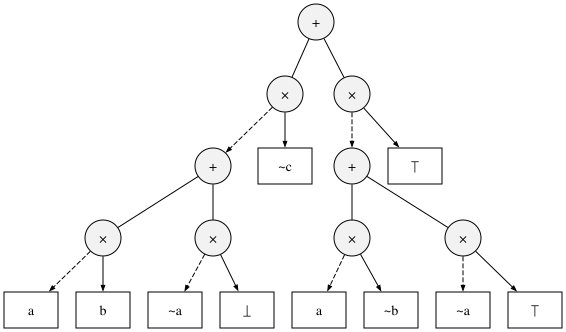

In [3]:
sdd = BuildMapper(solver="sdd", var_list=["a", "b", "c"])
a, b, c = sdd.Variables("a b c")
draw(sdd.BuildFormula(sdd.Implies(sdd.And(a, b), sdd.Not(c))).dot)

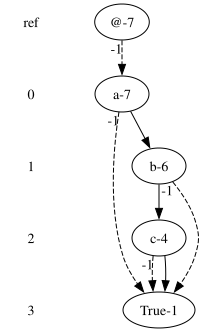

In [4]:
bdd = BuildMapper(solver="bdd", var_list=["a", "b", "c"])
a, b, c = bdd.Variables("a b c")
draw(bdd.BuildFormula(bdd.Implies(bdd.And(a, b), bdd.Not(c))).dot)

Formulas from the `bdd` interface also support Python's operators:

models: [{'a': False, 'b': False}, {'a': True, 'b': True}]


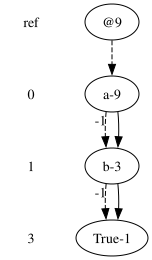

In [5]:
equivalence = (a & b) | (~a & ~b)

print("models:", list(bdd.Models(equivalence)))
draw(bdd.BuildFormula(equivalence).dot)

## SAT solvers

The `z3` and `pysat` interfaces use SAT solvers, which find models without compiling the whole formula, e.g., to detect contradictions:

In [6]:
z = BuildMapper(solver="z3", var_list=["a", "b"])
a, b = z.Variables("a b")
z.SAT(z.And(z.And(a, b), z.Not(a)))

SolverOut(inference_type=SAT, inference=unsat)

## Using interfaces in a `Solver`

A solver's interface is chosen with `_stype`. Weighted inference (`Prob`, `Viterbi`, ...) currently requires the default `sdd` interface; the others support satisfiability, counting and model enumeration:

In [7]:
solver = Solver(_stype="z3")
solver.add(["Implies(And(a, b), Not(c))"])
solver.add_weights({"a": 0.5, "b": 0.5, "c": 0.5})

print(
    solver.query(mode="SAT").inference, 
    solver.query(mode="Count", fast=True).inference
)

try:
    solver.query(mode="Prob")
except NotImplementedError as e:
    print("Prob:", e)

sat 7
Prob: WMC interface not implemented for this class
